# Jawaban Latihan Mandiri — Tugas Praktikum #3 (Multiprocessing)



---
## Soal 1 — Analisis Speedup Skala

**Rencana:**
1. Pakai `hitung_prima(n)` dari 7.1. Agar setiap jumlah worker punya cukup pekerjaan untuk dibagi, kita jalankan **8 tugas independen** (bukan 4), masing-masing `n = 80.000`.
2. Ukur waktu sekuensial sebagai baseline ($T_1$).
3. Ukur waktu dengan `Pool(processes=w)` untuk $w = 1, 2, 4, 8$ (diulang 3 kali, ambil waktu **tercepat** untuk mengurangi gangguan proses lain).
4. Hitung speedup aktual $S = T_1 / T_w$ dan bandingkan dengan Hukum Amdahl:

$$S_{\text{Amdahl}}(N) = \frac{1}{(1-P) + \frac{P}{N}}$$

dengan $P$ = porsi program yang bisa diparalelkan.

In [1]:
import os
import time
import multiprocessing as mp

def hitung_prima(n):
    # Menghitung semua bilangan prima hingga n (algoritma sederhana, sengaja tidak dioptimasi)
    primes = []
    for num in range(2, n):
        is_prime = True
        for i in range(2, int(num ** 0.5) + 1):
            if num % i == 0:
                is_prime = False
                break
        if is_prime:
            primes.append(num)
    return len(primes)

daftar_n = [80_000] * 8          # 8 tugas independen
jumlah_core = os.cpu_count() or 1
print("Jumlah core logis terdeteksi:", jumlah_core)

def ukur(fungsi, ulang=3):
    # Jalankan beberapa kali, ambil waktu tercepat
    terbaik = float("inf")
    hasil = None
    for _ in range(ulang):
        start = time.perf_counter()
        hasil = fungsi()
        terbaik = min(terbaik, time.perf_counter() - start)
    return terbaik, hasil

# --- Baseline sekuensial (T1) ---
waktu_seq, hasil_seq = ukur(lambda: [hitung_prima(n) for n in daftar_n])
print(f"[Sequential] hasil: {hasil_seq}  waktu: {waktu_seq:.2f} detik")

Jumlah core logis terdeteksi: 1


[Sequential] hasil: [7837, 7837, 7837, 7837, 7837, 7837, 7837, 7837]  waktu: 0.63 detik


In [2]:
ctx = mp.get_context('fork')   # konsisten: selalu pakai 'fork'
daftar_worker = [1, 2, 4, 8]
waktu_paralel = {}

def jalankan_pool(w):
    with ctx.Pool(processes=w) as pool:
        return pool.map(hitung_prima, daftar_n)

if __name__ == "__main__":
    for w in daftar_worker:
        t, hasil = ukur(lambda: jalankan_pool(w))
        assert hasil == hasil_seq, "Hasil paralel harus sama dengan sekuensial!"
        waktu_paralel[w] = t
        print(f"worker = {w}  waktu: {t:.2f} detik  speedup aktual: {waktu_seq / t:.2f}x")

worker = 1  waktu: 0.72 detik  speedup aktual: 0.87x


worker = 2  waktu: 0.59 detik  speedup aktual: 1.06x


worker = 4  waktu: 0.61 detik  speedup aktual: 1.03x


worker = 8  waktu: 0.64 detik  speedup aktual: 0.98x


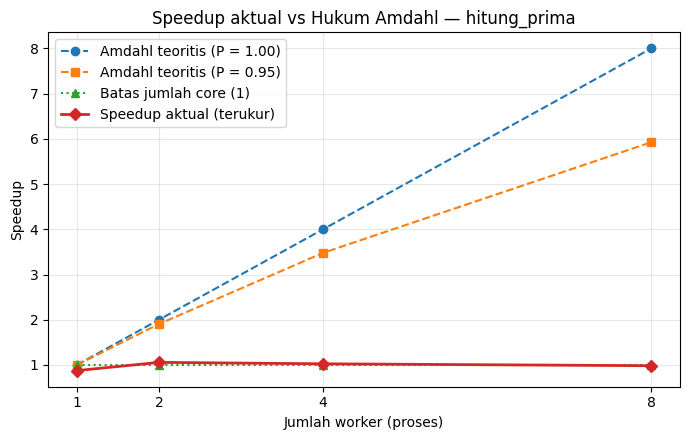

Worker | Waktu (s) |  Aktual | Amdahl P=1 | Amdahl P=.95 | Efisiensi
     1 |      0.72 |   0.87x |      1.00x |        1.00x |      87%
     2 |      0.59 |   1.06x |      2.00x |        1.90x |      53%
     4 |      0.61 |   1.03x |      4.00x |        3.48x |      26%
     8 |      0.64 |   0.98x |      8.00x |        5.93x |      12%


In [3]:
import matplotlib.pyplot as plt

speedup_aktual = [waktu_seq / waktu_paralel[w] for w in daftar_worker]

def amdahl(P, N):
    return 1 / ((1 - P) + P / N)

# P = 1.0 -> seluruh pekerjaan paralel (seperti di 7.1)
# P = 0.95 -> contoh jika 5% pekerjaan tetap serial (pembuatan Pool, pengiriman hasil, dll.)
amdahl_P100 = [amdahl(1.0, w) for w in daftar_worker]
amdahl_P95  = [amdahl(0.95, w) for w in daftar_worker]
# Batas praktis: speedup tidak bisa melebihi jumlah core yang benar-benar ada
batas_core  = [min(w, jumlah_core) for w in daftar_worker]

plt.figure(figsize=(7, 4.5))
plt.plot(daftar_worker, amdahl_P100, "o--", label="Amdahl teoritis (P = 1.00)")
plt.plot(daftar_worker, amdahl_P95,  "s--", label="Amdahl teoritis (P = 0.95)")
plt.plot(daftar_worker, batas_core,  "^:",  label=f"Batas jumlah core ({jumlah_core})")
plt.plot(daftar_worker, speedup_aktual, "D-", linewidth=2, label="Speedup aktual (terukur)")
plt.xticks(daftar_worker)
plt.xlabel("Jumlah worker (proses)")
plt.ylabel("Speedup")
plt.title("Speedup aktual vs Hukum Amdahl — hitung_prima")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f"{'Worker':>6} | {'Waktu (s)':>9} | {'Aktual':>7} | {'Amdahl P=1':>10} | {'Amdahl P=.95':>12} | {'Efisiensi':>9}")
for w, a, t1, t2 in zip(daftar_worker, speedup_aktual, amdahl_P100, amdahl_P95):
    print(f"{w:>6} | {waktu_paralel[w]:>9.2f} | {a:>6.2f}x | {t1:>9.2f}x | {t2:>11.2f}x | {a / w:>8.0%}")

### Penjelasan Soal 1

Kurva Amdahl menganggap kondisi ideal: setiap worker benar-benar berjalan **bersamaan** pada core-nya masing-masing, dan satu-satunya hal yang membatasi adalah porsi serial $(1-P)$. Kurva aktual biasanya berada **di bawah** kurva teoritis (dan bisa mendatar atau bahkan turun) karena beberapa hal:

1. **Jumlah core fisik terbatas.** Speedup tidak mungkin melebihi jumlah core yang tersedia. Jika mesin hanya punya 4 core, maka worker ke-5 sampai ke-8 tidak mendapat core baru; proses-proses itu hanya bergantian memakai core yang sama (*time-slicing*). Kurva aktual lalu mendatar di sekitar jumlah core, padahal Amdahl terus naik. Pada mesin dengan *hyper-threading*, 1 core fisik terlihat sebagai 2 core logis, tetapi keduanya berbagi unit eksekusi sehingga tambahan kecepatannya jauh lebih kecil dari 2×.
2. **Overhead pembuatan proses dan komunikasi.** Setiap worker harus di-*fork*, argumen tugas harus di-*pickle* lalu dikirim, dan hasilnya dikirim balik. Biaya ini hampir tetap atau bahkan naik seiring jumlah worker, sehingga untuk tugas yang pendek ia memakan sebagian besar keuntungan paralelisme. Inilah bagian $(1-P)$ "tersembunyi" yang tidak ada di model $P = 1$.
3. **Beban kerja lain di mesin.** Sistem operasi, browser, Jupyter kernel, dan aplikasi lain ikut memakai core. Karena itu worker kita tidak bisa mendapat 100% waktu CPU.
4. **Ketidakseimbangan beban (*load imbalance*).** Dengan 8 tugas dan 3 worker, misalnya, satu worker mendapat 3 tugas sementara yang lain 2–3, sehingga waktu total ditentukan worker yang paling lambat selesai.

Pada kasus 1 worker, speedup aktual bahkan bisa **sedikit di bawah 1×** karena kita membayar overhead pembuatan proses tanpa ada paralelisme sama sekali. Kesimpulannya: Hukum Amdahl memberi **batas atas** teoritis, sedangkan hasil nyata dibatasi oleh perangkat keras dan overhead.

---
## Soal 2 — Shared Memory vs Message Passing

Empat proses, masing-masing menjumlahkan **1 juta angka acak** (bilangan bulat 1–100). Agar kedua versi bisa dibandingkan adil dan hasilnya dapat diverifikasi, setiap proses memakai `random.Random(seed)` dengan seed = id proses, sehingga data yang dijumlahkan **identik** di kedua versi.

- **(a) Message passing:** tiap proses menghitung subtotal lalu mengirimnya lewat `Queue`; proses utama menjumlahkan 4 subtotal.
- **(b) Shared memory:** tiap proses langsung menambah ke `Value` bersama dengan `Lock`.
  - **(b1)** versi *persis seperti soal*: setiap angka langsung ditambahkan ke shared value (mengunci `Lock` 1 juta kali per proses).
  - **(b2)** versi *bonus*: akumulasi dulu di variabel lokal, lalu tambahkan ke shared value **sekali** saja.

In [4]:
import random
import time
import multiprocessing as mp

ctx = mp.get_context('fork')
JUMLAH_PROSES = 4
BANYAK_ANGKA = 1_000_000

def buat_data(seed):
    # Generator angka acak yang deterministik per proses
    rng = random.Random(seed)
    return (rng.randint(1, 100) for _ in range(BANYAK_ANGKA))

# Nilai acuan (dihitung sekuensial) untuk verifikasi kebenaran
total_acuan = sum(sum(buat_data(s)) for s in range(JUMLAH_PROSES))
print("Total acuan (sekuensial):", f"{total_acuan:,}")

# ---------- (a) Message passing: Queue ----------
def worker_queue(seed, antrian):
    subtotal = sum(buat_data(seed))
    antrian.put(subtotal)                # kirim HANYA 1 angka (subtotal) ke proses utama

def versi_queue():
    antrian = ctx.Queue()
    proses = [ctx.Process(target=worker_queue, args=(s, antrian)) for s in range(JUMLAH_PROSES)]
    for p in proses:
        p.start()
    # Ambil hasil SEBELUM join agar tidak terjadi deadlock saat queue masih berisi data
    total = sum(antrian.get() for _ in range(JUMLAH_PROSES))
    for p in proses:
        p.join()
    return total

# ---------- (b1) Shared memory: Value + Lock, tambah per angka ----------
def worker_value_per_angka(seed, total_bersama, lock):
    for angka in buat_data(seed):
        with lock:                       # kunci untuk SETIAP penambahan
            total_bersama.value += angka

def versi_value_per_angka():
    total_bersama = ctx.Value('q', 0)    # 'q' = signed long long (muat jumlah besar)
    lock = ctx.Lock()
    proses = [ctx.Process(target=worker_value_per_angka, args=(s, total_bersama, lock))
              for s in range(JUMLAH_PROSES)]
    for p in proses:
        p.start()
    for p in proses:
        p.join()
    return total_bersama.value

# ---------- (b2) Shared memory: akumulasi lokal, tambah sekali ----------
def worker_value_lokal(seed, total_bersama, lock):
    subtotal = sum(buat_data(seed))      # hitung di variabel lokal (tanpa lock)
    with lock:                           # kunci hanya 1 kali per proses
        total_bersama.value += subtotal

def versi_value_lokal():
    total_bersama = ctx.Value('q', 0)
    lock = ctx.Lock()
    proses = [ctx.Process(target=worker_value_lokal, args=(s, total_bersama, lock))
              for s in range(JUMLAH_PROSES)]
    for p in proses:
        p.start()
    for p in proses:
        p.join()
    return total_bersama.value

if __name__ == "__main__":
    hasil_tabel = []
    for nama, fungsi in [
        ("(a)  Queue (message passing)", versi_queue),
        ("(b1) Value + Lock per angka", versi_value_per_angka),
        ("(b2) Value + Lock, akumulasi lokal", versi_value_lokal),
    ]:
        start = time.perf_counter()
        total = fungsi()
        waktu = time.perf_counter() - start
        hasil_tabel.append((nama, total, waktu))

    print(f"\n{'Versi':<38} | {'Total':>13} | {'Benar?':>6} | {'Waktu (s)':>9}")
    print("-" * 78)
    for nama, total, waktu in hasil_tabel:
        print(f"{nama:<38} | {total:>13,} | {str(total == total_acuan):>6} | {waktu:>9.2f}")

Total acuan (sekuensial): 202,026,957



Versi                                  |         Total | Benar? | Waktu (s)
------------------------------------------------------------------------------
(a)  Queue (message passing)           |   202,026,957 |   True |      1.91
(b1) Value + Lock per angka            |   202,026,957 |   True |      6.00
(b2) Value + Lock, akumulasi lokal     |   202,026,957 |   True |      1.68


### Penjelasan Soal 2

- **Kebenaran:** ketiga versi menghasilkan total yang sama dengan nilai acuan. Pada (b1) dan (b2) hal ini hanya terjadi karena ada `Lock`; operasi `total.value += x` sebenarnya terdiri dari *baca → tambah → tulis* sehingga tanpa lock akan terjadi *race condition* dan sebagian penambahan hilang.
- **Performa:** versi **(b1) paling lambat** karena setiap proses melakukan 1 juta kali `acquire/release` lock, ditambah akses ke memori bersama yang di-*wrap* oleh `Value`. Lock itu juga memaksa keempat proses **bergantian** masuk ke bagian kritis, jadi paralelisme hampir hilang.
- **Versi (a) dan (b2) jauh lebih cepat** karena komunikasi/sinkronisasi hanya terjadi **sekali per proses**, bukan sekali per angka. Selisih keduanya kecil; keduanya sama-sama menjumlahkan secara lokal.
- **Pelajaran utama:** yang menentukan performa bukan sekadar *shared memory* vs *message passing*, melainkan **seberapa sering proses harus berkomunikasi atau mengunci**. Shared memory dengan lock yang terlalu sering dipakai bisa lebih lambat daripada message passing yang mengirim data ringkas. Resep umum: *hitung lokal sebanyak mungkin, sinkronkan sesedikit mungkin*.

---
## Soal 3 — Producer-Consumer Antar-Proses

Pola producer-consumer dari Pertemuan 2 memakai `threading.Thread` dan `queue.Queue`. Di sini kita buat **satu fungsi pipeline generik** yang menerima kelas `Queue` dan `Worker` sebagai parameter, sehingga:

- versi **thread** → `queue.Queue` + `threading.Thread`
- versi **proses** → `multiprocessing.Queue` + `multiprocessing.Process`

Dengan begitu perbedaan struktur kode bisa dilihat langsung (hanya dua baris yang berbeda). Beban kerjanya **CPU-bound**: consumer menjalankan `hitung_prima(n)`.

Detail desain:
- Producer memasukkan tugas ke `antrian_tugas`, lalu mengirim sinyal berhenti (*sentinel* `None`) satu per consumer.
- Consumer mengambil tugas, menghitung, dan mengirim hasil ke `antrian_hasil`.
- Proses utama mengambil semua hasil **sebelum** `join()` (menghindari deadlock pada `multiprocessing.Queue`).

In [5]:
import queue
import threading
import multiprocessing as mp
import os, time

ctx = mp.get_context('fork')
JUMLAH_CONSUMER = 4
DAFTAR_TUGAS = [60_000] * 8          # 8 tugas CPU-bound

def producer(antrian_tugas, tugas, jumlah_consumer):
    for n in tugas:
        antrian_tugas.put(n)
    for _ in range(jumlah_consumer):
        antrian_tugas.put(None)      # sentinel: "tidak ada tugas lagi"

def consumer(id_consumer, antrian_tugas, antrian_hasil):
    while True:
        n = antrian_tugas.get()
        if n is None:                # sentinel diterima -> berhenti
            break
        antrian_hasil.put((id_consumer, n, hitung_prima(n)))

def jalankan_pipeline(Queue, Worker, jumlah_consumer=JUMLAH_CONSUMER, tugas=DAFTAR_TUGAS):
    antrian_tugas, antrian_hasil = Queue(), Queue()
    prod = Worker(target=producer, args=(antrian_tugas, tugas, jumlah_consumer))
    cons = [Worker(target=consumer, args=(i, antrian_tugas, antrian_hasil))
            for i in range(jumlah_consumer)]
    start = time.perf_counter()
    prod.start()
    for c in cons:
        c.start()
    hasil = [antrian_hasil.get() for _ in range(len(tugas))]   # ambil dulu, baru join
    prod.join()
    for c in cons:
        c.join()
    return hasil, time.perf_counter() - start

if __name__ == "__main__":
    print("Core logis:", os.cpu_count())

    start = time.perf_counter()
    hasil_seq = [hitung_prima(n) for n in DAFTAR_TUGAS]
    waktu_seq = time.perf_counter() - start

    hasil_thread, waktu_thread = jalankan_pipeline(queue.Queue, threading.Thread)
    hasil_proses, waktu_proses = jalankan_pipeline(ctx.Queue, ctx.Process)

    # Verifikasi: semua versi menghasilkan jumlah prima yang sama
    print("Hasil thread benar? ", sorted(h[2] for h in hasil_thread) == sorted(hasil_seq))
    print("Hasil proses benar? ", sorted(h[2] for h in hasil_proses) == sorted(hasil_seq))
    print("Consumer (proses) yang terlibat:", sorted({h[0] for h in hasil_proses}))

    print(f"\n{'Versi':<34} | {'Waktu (s)':>9} | {'Speedup':>7}")
    print("-" * 58)
    print(f"{'Sekuensial':<34} | {waktu_seq:>9.2f} | {1.0:>6.2f}x")
    print(f"{'Thread  (queue.Queue)':<34} | {waktu_thread:>9.2f} | {waktu_seq / waktu_thread:>6.2f}x")
    print(f"{'Proses  (multiprocessing.Queue)':<34} | {waktu_proses:>9.2f} | {waktu_seq / waktu_proses:>6.2f}x")

Core logis: 1


Hasil thread benar?  True
Hasil proses benar?  True
Consumer (proses) yang terlibat: [0, 1, 2, 3]

Versi                              | Waktu (s) | Speedup
----------------------------------------------------------
Sekuensial                         |      0.39 |   1.00x
Thread  (queue.Queue)              |      0.41 |   0.96x
Proses  (multiprocessing.Queue)    |      0.50 |   0.79x


### Penjelasan Soal 3

**Apakah struktur kode banyak berubah?** Tidak. Fungsi `producer` dan `consumer` **sama persis**; satu-satunya perubahan ada pada pemanggilan `jalankan_pipeline`: `queue.Queue` → `multiprocessing.Queue` dan `threading.Thread` → `multiprocessing.Process`. Antarmuka `put()`, `get()`, `start()`, `join()` sengaja dibuat mirip. Hal-hal yang perlu diperhatikan saat berpindah ke proses:

| Aspek | Thread | Proses |
|---|---|---|
| Memori | Dibagi otomatis | Terpisah; data dikirim lewat Queue (di-*pickle*) |
| Data yang dikirim lewat Queue | Cukup referensi objek | Harus bisa di-*pickle* |
| Deadlock saat `join()` | Jarang | Bisa terjadi jika Queue masih berisi data → ambil hasil dulu sebelum `join()` |
| Pembuatan | Murah | Lebih mahal (proses OS baru) |

**Perbedaan performa pada tugas CPU-bound:**
- Versi **thread** hampir tidak lebih cepat dari sekuensial (speedup ≈ 1×, kadang sedikit lebih lambat) karena **GIL** hanya mengizinkan satu thread menjalankan bytecode Python pada satu waktu, sehingga consumer yang CPU-bound tidak benar-benar berjalan paralel. Berbeda dengan Pertemuan 2 yang I/O-bound: di sana thread sering **menunggu** I/O dan melepas GIL, jadi thread tetap bermanfaat.
- Versi **proses** tiap consumer punya interpreter dan GIL sendiri, sehingga dapat berjalan paralel di core berbeda. Speedup-nya mendekati jumlah core yang tersedia (maksimal `min(jumlah consumer, jumlah core)`), dikurangi overhead pembuatan proses dan pengiriman data lewat Queue.
- Jika mesin hanya punya **1 core**, versi proses pun tidak akan lebih cepat (bahkan sedikit lebih lambat karena overhead), karena tidak ada core tambahan yang bisa dipakai. Di mesin multi-core, perbedaan thread vs proses akan terlihat jelas.

---
## Soal 4 — Refleksi Singkat (maks. 150 kata)

**Kapan memilih `Manager()` dibanding `Value`/`Array`:**
Saya memilih `Manager()` saat data bersama berstruktur kompleks dan dinamis, misalnya `dict` hasil per-pengguna atau `list` log yang ukurannya tidak diketahui di awal dan diubah banyak proses. `Value`/`Array` hanya mendukung tipe primitif berukuran tetap, sehingga tidak cocok. Dalam skenario ini kemudahan pengembangan lebih penting karena akses tidak terlalu sering.

**Kapan memilih sebaliknya:**
Saya memilih `Value`/`Array` untuk penghitung atau buffer numerik yang diakses sangat sering, misalnya progres, statistik, atau array piksel. Memorinya benar-benar dibagikan sehingga cepat, sementara `Manager()` lambat karena tiap akses adalah panggilan IPC ke proses server.

**Trade-off:** `Manager()` = mudah tetapi lambat; `Value`/`Array` = cepat tetapi terbatas dan perlu `Lock` manual.

In [6]:
# Pengecekan jumlah kata refleksi (batas maksimal 150 kata)
import re
refleksi = '''
Saya memilih Manager() saat data bersama berstruktur kompleks dan dinamis, misalnya dict hasil per-pengguna atau list log yang ukurannya tidak diketahui di awal dan diubah banyak proses. Value/Array hanya mendukung tipe primitif berukuran tetap, sehingga tidak cocok. Dalam skenario ini kemudahan pengembangan lebih penting karena akses tidak terlalu sering.
Saya memilih Value/Array untuk penghitung atau buffer numerik yang diakses sangat sering, misalnya progres, statistik, atau array piksel. Memorinya benar-benar dibagikan sehingga cepat, sementara Manager() lambat karena tiap akses adalah panggilan IPC ke proses server.
Trade-off: Manager() = mudah tetapi lambat; Value/Array = cepat tetapi terbatas dan perlu Lock manual.
'''
print("Jumlah kata:", len(re.findall(r"\S+", refleksi)))

Jumlah kata: 99
